# # 02 · EDA and normality assessment (M2)
#
# **Questions:** What do pollutant levels look like across states, cities, seasons and location types?
# Are the concentrations normally distributed, and does a log or Box-Cox transform help?
#
# Data: `data/clean/air_quality_final.csv` (3,778 station-days, 71 stations, 30 cities, 3 states, 2015).
# Figures follow the team style guide (`docs/style_guide.md`) and are exported to `figures/`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from IPython.display import display

from src.style import apply_style, save_fig, save_table, STATE_COLORS, POLLUTANT_COLORS, LABELS, ACCENT, FIGSIZE
from src.data import load_clean, load_master, POLLUTANTS, STATE_ORDER, SEASON_ORDER

apply_style()
pd.set_option("display.width", 160, "display.max_columns", 30)
RNG = np.random.default_rng(42)
df = load_clean()
print(df.shape, df.station.nunique(), "stations", df.city.nunique(), "cities")

(3778, 23) 71 stations 30 cities


# ## 1. Summary statistics
# Mean, median, SD, IQR, min, max, skewness, excess kurtosis and coefficient of variation (CV = SD / mean).

In [2]:
def describe(x):
    x = x.dropna()
    q1, q3 = x.quantile([.25, .75])
    return pd.Series({"n": len(x), "mean": x.mean(), "median": x.median(), "sd": x.std(),
                      "iqr": q3 - q1, "min": x.min(), "max": x.max(),
                      "skewness": stats.skew(x), "kurtosis": stats.kurtosis(x),
                      "cv_%": 100 * x.std() / x.mean()})

overall = pd.DataFrame({p: describe(df[p]) for p in POLLUTANTS + ["AQI"]}).T.round(2)
display(overall)
save_table(overall, "m2_summary_overall", index=True)

,n,mean,median,sd,iqr,min,max,skewness,kurtosis,cv_%
SO2,3778.0,8.15,7.0,5.93,11.0,2.0,84.0,1.27,8.30,72.81
NO2,3778.0,24.04,21.0,13.97,10.0,5.0,125.0,2.06,5.23,58.10
PM10,3778.0,92.96,86.5,40.12,31.0,15.0,590.0,2.72,17.46,43.16
PM25,3778.0,43.01,36.0,25.24,20.0,5.0,331.0,2.81,15.55,58.68
AQI,3778.0,99.16,88.0,51.37,31.3,20.0,494.1,2.46,8.25,51.80


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m2_summary_overall.csv')

In [3]:
long = df.melt(id_vars=["state", "city"], value_vars=POLLUTANTS, var_name="pollutant")
by_state = long.groupby(["pollutant", "state"])["value"].apply(describe).unstack().round(2)
display(by_state)
save_table(by_state, "m2_summary_by_state", index=True)

by_city = long.groupby(["pollutant", "state", "city"])["value"].apply(describe).unstack().round(2)
save_table(by_city, "m2_summary_by_city", index=True)
display(by_city.loc["PM25"].sort_values("mean", ascending=False).head(10))

n    mean  median     sd    iqr   min    max  skewness  kurtosis   cv_%
pollutant state                                                                                    
NO2       Gujarat      1080.0   20.89    21.0   2.12   2.00  12.0   37.0      1.53      5.97  10.14
          Odisha       2060.0   18.06    17.0   6.95  11.25   5.0   44.0      0.59     -0.67  38.50
          West Bengal   638.0   48.65    49.0  15.92  22.00  16.0  125.0      0.63      1.31  32.72
PM10      Gujarat      1080.0   86.97    86.0  10.52  12.00  53.0  180.0      2.01     14.01  12.09
          Odisha       2060.0   89.41    84.0  41.16  44.00  15.0  590.0      2.70     21.32  46.03
          West Bengal   638.0  114.53   104.0  57.57  66.75  30.0  411.0      1.40      2.86  50.27
PM25      Gujarat      1080.0   31.05    31.0   5.09   6.00   9.0   48.0     -0.60      2.09  16.41
          Odisha       2060.0   42.47    40.0  24.22  22.00   5.0  331.0      2.97     19.85  57.03
          West Bengal   638.0   64.98    62.0  33.31  47.00  15.0  303.0      1.50      6.04  51.26
SO2       Gujarat      1080.0   14.37    14.0   3.04   2.00   6.0   31.0      1.85      4.46  21.14
          Odisha       2060.0    5.16     3.0   4.31   6.00   2.0   37.0      1.51      2.69  83.67
          West Bengal   638.0    7.27     6.0   6.13   6.00   2.0   84.0      4.86     48.25  84.21

n   mean  median     sd    iqr   min    max  skewness  kurtosis   cv_%
state       city                                                                                   
Odisha      TALCHER      104.0  82.39    81.0  32.58  46.00  17.0  173.0      0.48     -0.20  39.54
West Bengal BARRACKPORE  104.0  75.75    72.0  21.53  30.25  29.0  146.0      0.48      0.35  28.43
            HOWRAH       104.0  72.82    74.0  32.62  26.50  20.0  303.0      3.51     23.07  44.80
            DURGAPUR     102.0  67.66    65.0  23.84  35.00  26.0  145.0      0.60      0.30  35.24
Odisha      ANGUL        210.0  58.82    55.0  20.86  21.00  25.0  137.0      1.28      1.92  35.46
West Bengal KOLKATA      328.0  58.25    44.5  37.42  53.00  15.0  251.0      1.52      3.20  64.24
Odisha      BALASORE      50.0  53.82    52.0  11.86  17.75  32.0   88.0      0.76      0.41  22.03
            ROURKELA     296.0  49.84    45.5  18.86  18.00   9.0  129.0      1.24      2.54  37.84
            SAMBALPUR     38.0  49.79    50.0   3.66   5.50  44.0   58.0      0.53     -0.38   7.34
            KEONJHAR      76.0  44.57    39.5  25.41  26.50   5.0  118.0      1.02      0.75  57.01

# **Reading:** every pollutant has mean > median and positive skewness (a right tail of high-pollution days).
# PM10 is the largest by mass; PM2.5 is roughly half of PM10. CVs of 40–70% show large day-to-day and
# station-to-station variation. West Bengal has the highest particulate levels, Gujarat the lowest
# and least variable.

# ## 2. Distributions: histograms

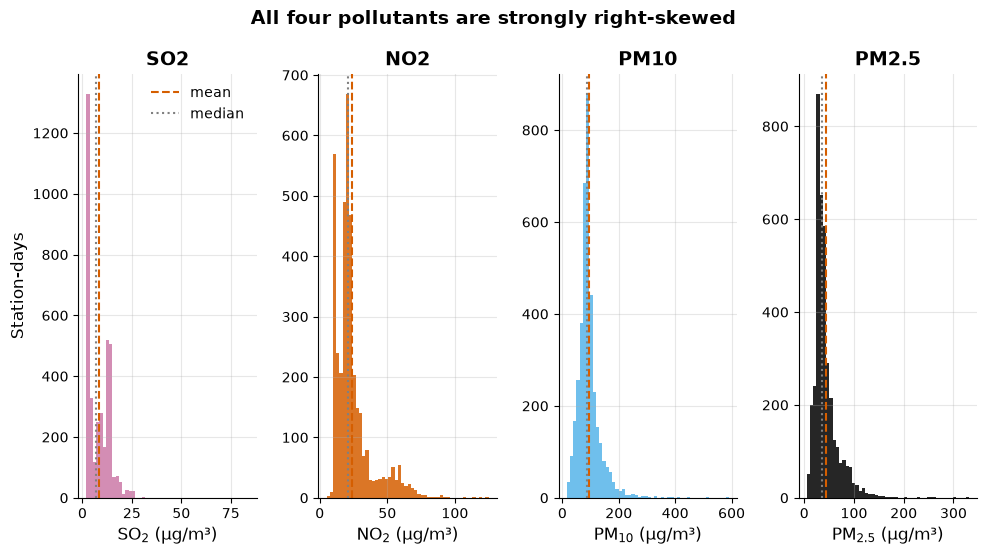

In [4]:
fig, axes = plt.subplots(1, 4, figsize=FIGSIZE)
for ax, p in zip(axes, POLLUTANTS):
    ax.hist(df[p], bins=50, color=POLLUTANT_COLORS[p], alpha=.85)
    ax.axvline(df[p].mean(), color=ACCENT, ls="--", lw=1.5, label="mean")
    ax.axvline(df[p].median(), color="grey", ls=":", lw=1.5, label="median")
    ax.set_xlabel(LABELS[p]); ax.set_title(p.replace("PM25", "PM2.5"))
axes[0].set_ylabel("Station-days"); axes[0].legend()
fig.suptitle("All four pollutants are strongly right-skewed", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m2_histograms"); plt.show()

# ## 3. Boxplots by state, city, season and location type

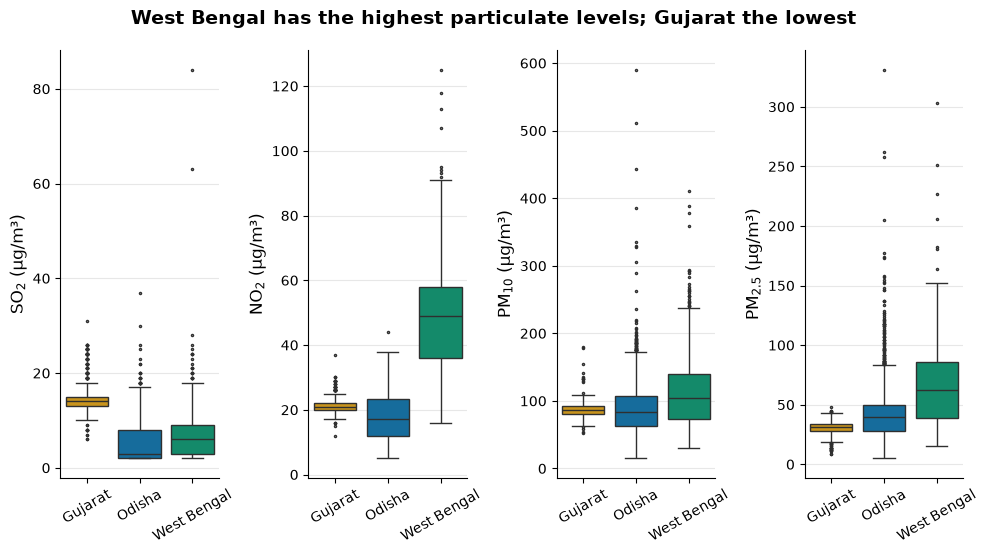

In [5]:
fig, axes = plt.subplots(1, 4, figsize=FIGSIZE)
for ax, p in zip(axes, POLLUTANTS):
    sns.boxplot(data=df, x="state", y=p, order=STATE_ORDER, hue="state", hue_order=STATE_ORDER,
                palette=STATE_COLORS, legend=False, ax=ax, fliersize=1.5, linewidth=1)
    ax.set_xlabel(""); ax.set_ylabel(LABELS[p]); ax.tick_params(axis="x", rotation=30)
fig.suptitle("West Bengal has the highest particulate levels; Gujarat the lowest", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m2_boxplot_by_state"); plt.show()

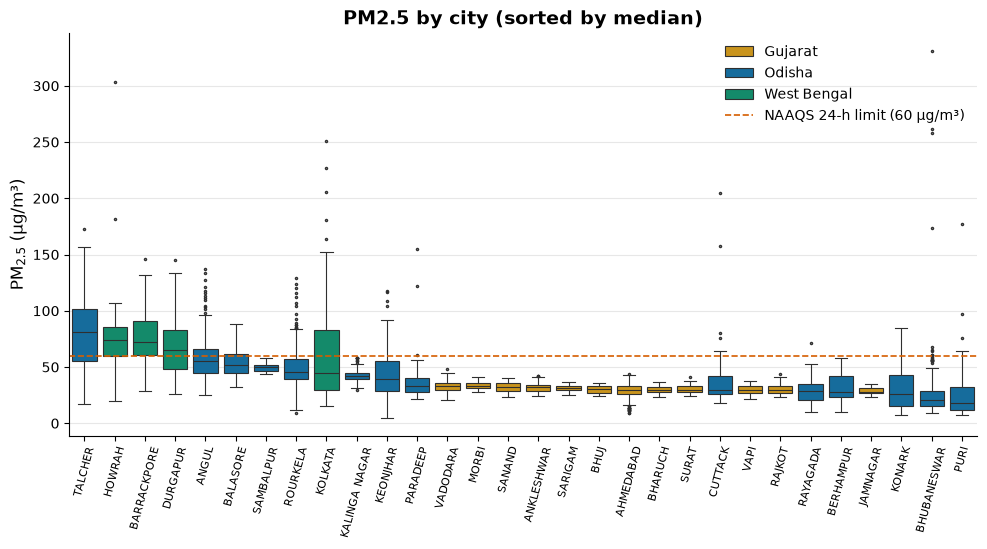

In [6]:
order = df.groupby("city").PM25.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.boxplot(data=df, x="city", y="PM25", order=order, hue="state", hue_order=STATE_ORDER,
            palette=STATE_COLORS, dodge=False, fliersize=1.5, linewidth=.8, ax=ax)
ax.axhline(60, color=ACCENT, ls="--", lw=1.2, label="NAAQS 24-h limit (60 µg/m³)")
ax.set_xlabel(""); ax.set_ylabel(LABELS["PM25"]); ax.tick_params(axis="x", rotation=75, labelsize=8)
ax.set_title("PM2.5 by city (sorted by median)"); ax.legend(loc="upper right")
fig.tight_layout(); save_fig(fig, "m2_boxplot_pm25_by_city"); plt.show()

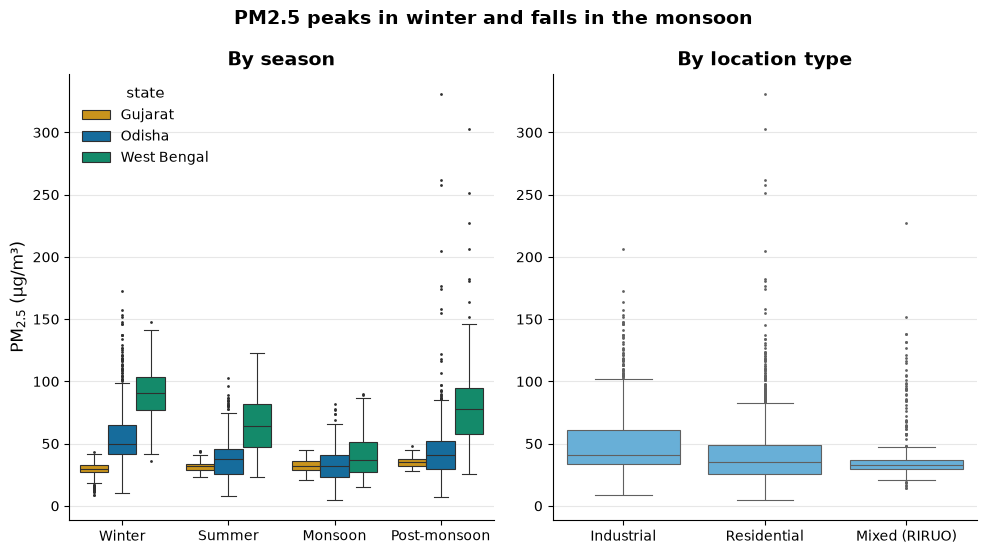

In [7]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
sns.boxplot(data=df, x="season", y="PM25", hue="state", order=SEASON_ORDER, hue_order=STATE_ORDER,
            palette=STATE_COLORS, fliersize=1, linewidth=.8, ax=axes[0])
axes[0].set_ylabel(LABELS["PM25"]); axes[0].set_xlabel(""); axes[0].set_title("By season")
sns.boxplot(data=df, x="location_class", y="PM25", order=["Industrial", "Residential", "Mixed (RIRUO)"],
            color="#56B4E9", fliersize=1, linewidth=.8, ax=axes[1])
axes[1].set_ylabel(""); axes[1].set_xlabel(""); axes[1].set_title("By location type")
fig.suptitle("PM2.5 peaks in winter and falls in the monsoon", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m2_boxplot_pm25_season_location"); plt.show()

# ## 4. Time-series plots
# Thin lines: weekly mean of each state's station-days. Thick lines: monthly mean.

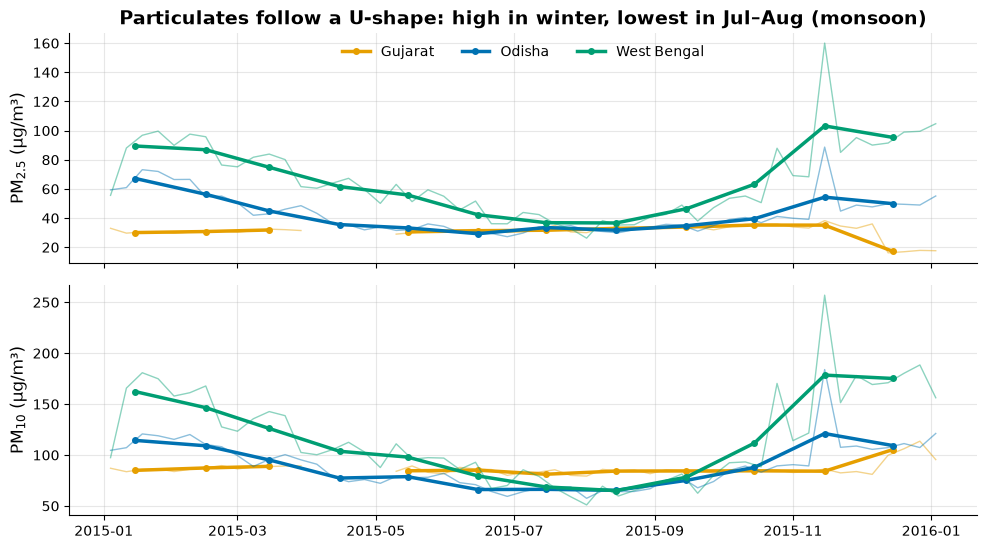

In [8]:
fig, axes = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True)
for ax, p in zip(axes, ["PM25", "PM10"]):
    for s in STATE_ORDER:
        ser = df[df.state == s].set_index("date")[p]
        w = ser.resample("W").mean()
        ax.plot(w.index, w, color=STATE_COLORS[s], lw=1, alpha=.45)
        m = ser.resample("MS").mean()
        ax.plot(m.index + pd.Timedelta(days=14), m, color=STATE_COLORS[s], lw=2.5, marker="o", ms=4, label=s)
    ax.set_ylabel(LABELS[p])
axes[0].legend(ncol=3, loc="upper center")
axes[0].set_title("Particulates follow a U-shape: high in winter, lowest in Jul–Aug (monsoon)")
fig.tight_layout(); save_fig(fig, "m2_timeseries_particulates"); plt.show()

In [9]:
monthly = df.groupby(["state", "month"])[POLLUTANTS].mean().round(1)
save_table(monthly, "m2_monthly_means_by_state", index=True)
display(monthly["PM25"].unstack(0))

state,Gujarat,Odisha,West Bengal
month,,,
1,30.1,67.2,89.4
2,30.8,56.3,86.9
3,31.8,44.9,74.8
4,NaN,35.6,61.6
5,30.5,33.3,55.9
6,31.4,29.3,42.3
7,31.7,33.5,36.9
8,32.9,31.7,36.6
9,33.9,34.7,46.4


# ## 5. Scatterplot matrix (log scale)

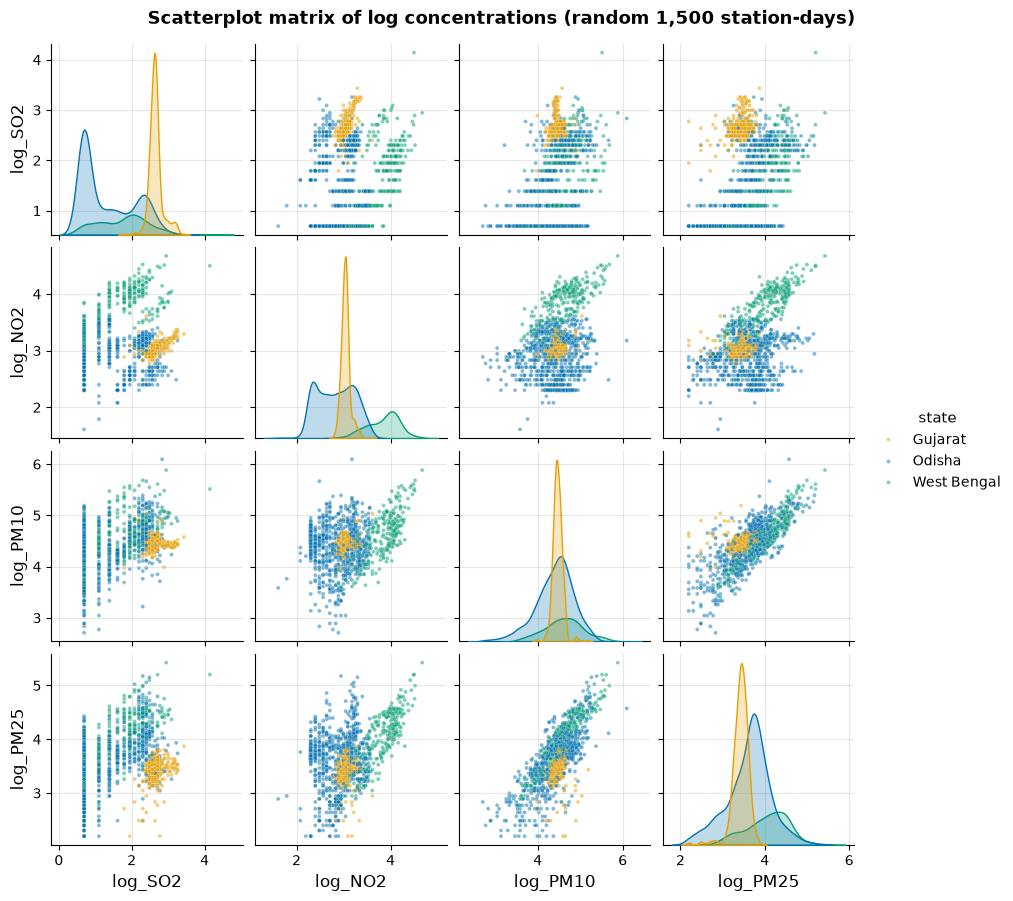

In [10]:
sub = df.sample(1500, random_state=42)
g = sns.pairplot(sub, vars=[f"log_{p}" for p in POLLUTANTS], hue="state", hue_order=STATE_ORDER,
                 palette=STATE_COLORS, plot_kws={"s": 8, "alpha": .5}, diag_kind="kde", height=2.2)
g.fig.suptitle("Scatterplot matrix of log concentrations (random 1,500 station-days)", y=1.02, fontweight="bold")
save_fig(g.fig, "m2_scatter_matrix"); plt.show()

# PM10 and PM2.5 move together tightly; NO2 is moderately related to the particulates; SO2 shows the
# detection floor as a vertical stripe at log(2) ≈ 0.69.

# ## 6. Missingness (before complete-case filtering)
# Uses `air_quality_master.csv`, which still contains the 2,192 incomplete records.

,SO2,NO2,PM10,PM25
state,,,,
Gujarat,0.1,0.1,0.1,0.1
Odisha,0.0,0.0,0.0,13.9
West Bengal,0.3,0.3,0.0,74.4


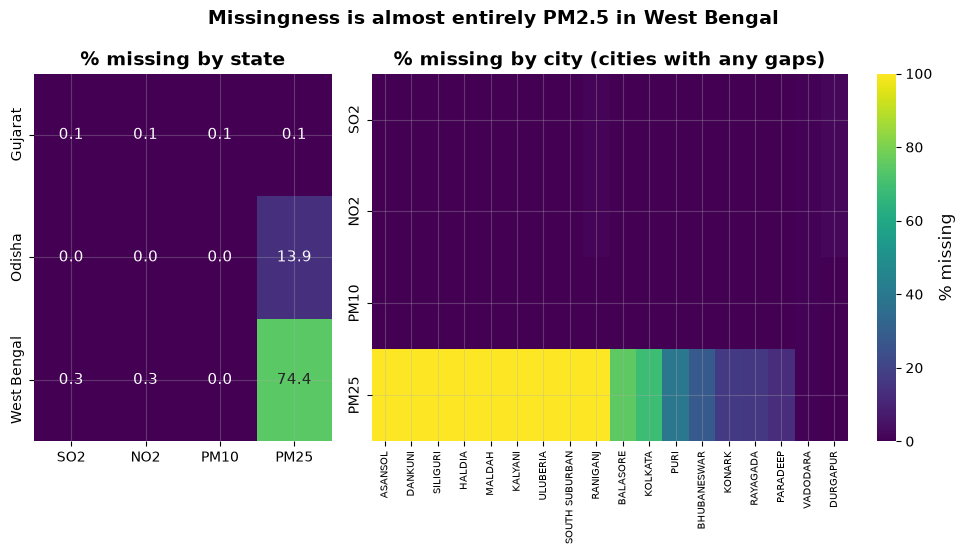

In [11]:
master = load_master()
miss_state = master.groupby("state")[POLLUTANTS].apply(lambda d: d.isna().mean() * 100).round(1)
display(miss_state)
save_table(miss_state, "m2_missing_pct_by_state", index=True)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1, 2]})
sns.heatmap(miss_state, annot=True, fmt=".1f", cmap="viridis", vmin=0, vmax=100, cbar=False, ax=axes[0])
axes[0].set_title("% missing by state"); axes[0].set_ylabel("")
mc = master.groupby("city")[POLLUTANTS].apply(lambda d: d.isna().mean() * 100)
mc = mc[mc.sum(axis=1) > 0].sort_values("PM25", ascending=False)
sns.heatmap(mc.T, cmap="viridis", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=axes[1])
axes[1].set_title("% missing by city (cities with any gaps)"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", labelsize=7, rotation=90)
fig.suptitle("Missingness is almost entirely PM2.5 in West Bengal", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m2_missingness_heatmap"); plt.show()

# **Implication:** complete-case analysis keeps 4 of 13 West Bengal cities. West Bengal estimates refer to
# those stations (mainly the Kolkata area), which we state as a limitation.

# ## 7. Normality assessment
#
# For each pollutant on three scales (raw, log, Box-Cox) we run:
# - **Shapiro–Wilk** (valid up to n = 5,000, so on all 3,778 rows),
# - **D'Agostino–Pearson** (based on skewness and kurtosis),
# - **Anderson–Darling** (statistic A² compared with the 5% critical value),
# - **Kolmogorov–Smirnov, Lilliefors version** (mean and SD estimated from the data).
#
# H0: the data come from a normal distribution; α = 0.05.
# With n ≈ 3,800 these tests detect even trivial departures, so we judge mainly by skewness and Q-Q plots,
# and repeat the tests on a random subsample of n = 200 to show what happens at a moderate sample size.

In [12]:
def normality_tests(x):
    x = np.asarray(x)
    out = []
    sw = stats.shapiro(x)
    out.append(("Shapiro-Wilk", sw.statistic, sw.pvalue, None))
    dp = stats.normaltest(x)
    out.append(("D'Agostino-Pearson", dp.statistic, dp.pvalue, None))
    ad = stats.anderson(x, dist="norm")
    crit5 = ad.critical_values[list(ad.significance_level).index(5.0)]
    out.append(("Anderson-Darling", ad.statistic, None, crit5))
    ks_stat, ks_p = lilliefors(x, dist="norm")
    out.append(("KS (Lilliefors)", ks_stat, ks_p, None))
    return out

rows, bc_lambda = [], {}
for p in POLLUTANTS:
    raw = df[p].values
    bc, lam = stats.boxcox(raw)
    bc_lambda[p] = lam
    for tname, x in [("none", raw), ("log", np.log(raw)), (f"Box-Cox (λ={lam:.2f})", bc)]:
        for sample, xs in [("full", x), ("n=200", RNG.choice(x, 200, replace=False))]:
            for test, stat, pval, crit in normality_tests(xs):
                if crit is not None:
                    reject = stat > crit
                    ptxt = f"crit5%={crit:.3f}"
                else:
                    reject = pval < .05
                    ptxt = f"{pval:.2e}" if pval < .001 else f"{pval:.3f}"
                rows.append({"variable": p, "transform": tname, "sample": sample, "test": test,
                             "statistic": round(stat, 4), "p_value": ptxt,
                             "decision": "Reject H0" if reject else "Do not reject",
                             "skewness": round(stats.skew(xs), 2), "kurtosis": round(stats.kurtosis(xs), 2)})
norm_table = pd.DataFrame(rows)
save_table(norm_table, "m2_normality_tests")
display(norm_table[norm_table["sample"] == "full"])

,variable,transform,sample,test,statistic,p_value,decision,skewness,kurtosis
0,SO2,none,full,Shapiro-Wilk,0.8571,3.80e-50,Reject H0,1.27,8.30
1,SO2,none,full,D'Agostino-Pearson,1230.9673,5.00e-268,Reject H0,1.27,8.30
2,SO2,none,full,Anderson-Darling,143.3130,crit5%=0.752,Reject H0,1.27,8.30
3,SO2,none,full,KS (Lilliefors),0.1620,1.00e-03,Reject H0,1.27,8.30
8,SO2,log,full,Shapiro-Wilk,0.8582,5.07e-50,Reject H0,-0.16,-1.53
9,SO2,log,full,D'Agostino-Pearson,22146.8285,0.00e+00,Reject H0,-0.16,-1.53
10,SO2,log,full,Anderson-Darling,210.6335,crit5%=0.752,Reject H0,-0.16,-1.53
11,SO2,log,full,KS (Lilliefors),0.1936,1.00e-03,Reject H0,-0.16,-1.53
16,SO2,Box-Cox (λ=0.16),full,Shapiro-Wilk,0.8693,1.17e-48,Reject H0,-0.07,-1.45
17,SO2,Box-Cox (λ=0.16),full,D'Agostino-Pearson,28120.2178,0.00e+00,Reject H0,-0.07,-1.45


In [13]:
compact = (norm_table.assign(reject=norm_table.decision.eq("Reject H0"))
           .groupby(["variable", "transform", "sample"], sort=False)
           .agg(skewness=("skewness", "first"), kurtosis=("kurtosis", "first"),
                tests_rejecting=("reject", "sum")).unstack("sample"))
compact.columns = [f"{a}_{b}" for a, b in compact.columns]
compact = compact[["skewness_full", "kurtosis_full", "tests_rejecting_full", "tests_rejecting_n=200"]]
display(compact)
save_table(compact, "m2_normality_summary", index=True)

skewness_full  kurtosis_full  tests_rejecting_full  tests_rejecting_n=200
variable transform                                                                                   
SO2      none                        1.27           8.30                     4                      4
         log                        -0.16          -1.53                     4                      4
         Box-Cox (λ=0.16)           -0.07          -1.45                     4                      4
NO2      none                        2.06           5.23                     4                      4
         log                         0.56           0.26                     4                      4
         Box-Cox (λ=-0.40)           0.01          -0.19                     4                      3
PM10     none                        2.72          17.46                     4                      4
         log                        -0.24           2.06                     4                      4
         Box-Cox (λ=0.11)            0.03           2.09                     4                      4
PM25     none                        2.81          15.55                     4                      4
         log                         0.19           0.91                     4                      3
         Box-Cox (λ=-0.10)          -0.01           0.93                     4                      3

WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m2_normality_summary.csv')

# ## 8. Visual checks: histogram with fitted normal curve and Q-Q plots, raw vs log

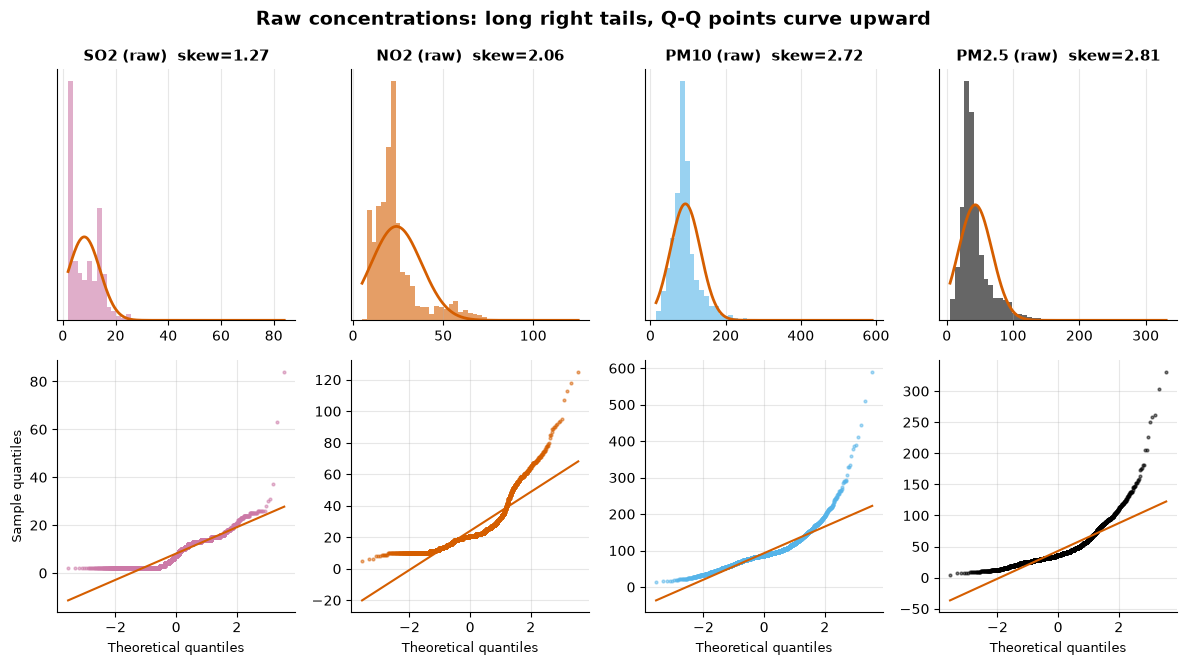

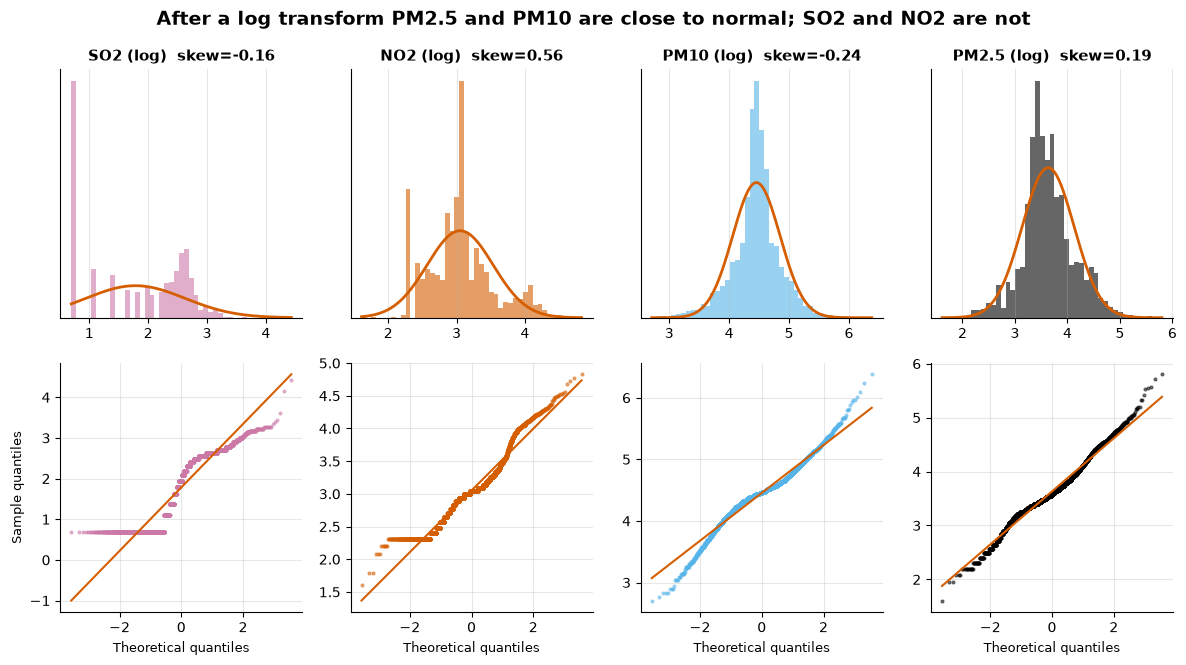

In [14]:
for scale in ["raw", "log"]:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.75))
    for j, p in enumerate(POLLUTANTS):
        x = df[p].values if scale == "raw" else np.log(df[p].values)
        ax = axes[0, j]
        ax.hist(x, bins=45, density=True, color=POLLUTANT_COLORS[p], alpha=.6)
        xs = np.linspace(x.min(), x.max(), 300)
        ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), color=ACCENT, lw=2)
        ax.set_title(f"{p.replace('PM25','PM2.5')} ({scale})  skew={stats.skew(x):.2f}", fontsize=11)
        ax.set_yticks([])
        stats.probplot(x, dist="norm", plot=axes[1, j])
        axes[1, j].get_lines()[0].set(markersize=2, color=POLLUTANT_COLORS[p], alpha=.5)
        axes[1, j].get_lines()[1].set(color=ACCENT)
        axes[1, j].set_title(""); axes[1, j].set_xlabel("Theoretical quantiles", fontsize=9)
        axes[1, j].set_ylabel("Sample quantiles" if j == 0 else "", fontsize=9)
    ttl = ("Raw concentrations: long right tails, Q-Q points curve upward" if scale == "raw"
           else "After a log transform PM2.5 and PM10 are close to normal; SO2 and NO2 are not")
    fig.suptitle(ttl, fontweight="bold", fontsize=14)
    fig.tight_layout(); save_fig(fig, f"m2_qq_hist_{scale}"); plt.show()

# ## 9. Normality within groups (what M3's tests actually rely on)
# Skewness of log PM2.5 within each state × season cell.

In [15]:
grp = df.groupby(["state", "season"], observed=True).log_PM25.agg(
    n="size", skewness=lambda x: stats.skew(x), kurtosis=lambda x: stats.kurtosis(x),
    shapiro_p=lambda x: stats.shapiro(x).pvalue).round(3)
display(grp)
save_table(grp, "m2_normality_logpm25_by_group", index=True)
print("Box-Cox lambdas:", {k: round(v, 3) for k, v in bc_lambda.items()})

n  skewness  kurtosis  shapiro_p
state       season                                          
Gujarat     Winter        547    -2.154     7.120      0.000
            Summer        270    -0.026    -0.176      0.075
            Monsoon       171    -0.409    -0.008      0.028
            Post-monsoon   92     0.352    -0.299      0.138
Odisha      Winter        508    -0.207     0.871      0.000
            Summer        487    -0.551     0.006      0.000
            Monsoon       670    -0.769     0.286      0.000
            Post-monsoon  395     0.073     1.859      0.000
West Bengal Winter        142    -0.670     0.818      0.001
            Summer        126    -0.611    -0.260      0.001
            Monsoon       245     0.065    -0.896      0.002
            Post-monsoon  125     0.316     0.610      0.102

Box-Cox lambdas: {'SO2': np.float64(0.156), 'NO2': np.float64(-0.403), 'PM10': np.float64(0.115), 'PM25': np.float64(-0.095)}


# ## 10. Conclusions (for slides 5–6)
#
# 1. **Levels.** Mean PM2.5 is 43 µg/m³ (median 36) and PM10 93 µg/m³ (median 87). West Bengal (stations
#    with PM2.5, mainly the Kolkata area) is highest: mean PM2.5 65 µg/m³, above the 24-h NAAQS of 60.
#    Odisha averages 42 and Gujarat 31. West Bengal NO2 (49 µg/m³) is more than double the other states.
# 2. **Seasonality.** Particulates follow a U-shape over the year in Odisha and West Bengal: highest in
#    Nov–Feb (WB ≈ 90–100 µg/m³ PM2.5), lowest in Jun–Aug (≈ 30–40), consistent with monsoon washout and
#    winter inversions. Gujarat is almost flat all year.
# 3. **Gujarat data look unusually smooth** (CV of PM2.5 16%, NO2 10%, versus 50–60% elsewhere). This may
#    reflect the reporting practice of those stations; treat Gujarat comparisons with caution.
# 4. **Normality – raw scale.** All four pollutants are strongly right-skewed (skewness 1.3–2.8, excess
#    kurtosis 5–17). All four tests reject normality for every pollutant, and the Q-Q plots curve upward.
# 5. **Normality – log / Box-Cox.** Box-Cox λ is close to 0 for PM2.5 (−0.10) and PM10 (0.11), i.e. a log
#    is the right transform. After logging, skewness drops to 0.19 (PM2.5) and −0.24 (PM10) and the Q-Q
#    plots are close to straight. The formal tests still reject on the full sample (n = 3,778 makes them
#    sensitive to tiny departures, plus the data are a mixture of states and seasons), and still reject at
#    n = 200 for some tests because of moderately heavy tails. Within single state × season groups, several
#    cells pass Shapiro-Wilk on log PM2.5.
# 6. **SO2 and NO2** are not normal on any scale: SO2 is censored at the 2 µg/m³ detection floor (29% of
#    values) and NO2 is a mixture of Gujarat's near-constant ~21 µg/m³ and much more variable values
#    elsewhere.
# 7. **Decision for the team.** Use **log-transformed** pollutants in t-tests, ANOVA, factor analysis and
#    regression (results read as ratios of geometric means), always with a **non-parametric** check
#    (Mann-Whitney, Kruskal-Wallis, Spearman). With n in the hundreds, the t-test and ANOVA are robust to
#    the remaining mild non-normality by the central limit theorem.